<a href="https://colab.research.google.com/github/Priyankaewp/schools-project/blob/main/DataCleaningDay3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("titanic.csv.xlsx")
print(df.shape)

(891, 15)


In [3]:
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [4]:
# Text Cleaning
df['embark_town'] = (df["embark_town"]
                     .astype("string")
                     .str.strip()
                     .str.title())

In [5]:
# deck
df['deck'] = (df["deck"]
              .astype("string")
              .str.strip()
              .str.upper())
print(df[["embark_town", "deck"]].head(10))

   embark_town  deck
0  Southampton  <NA>
1    Cherbourg     C
2  Southampton  <NA>
3  Southampton     C
4  Southampton  <NA>
5   Queenstown  <NA>
6  Southampton     E
7  Southampton  <NA>
8  Southampton  <NA>
9    Cherbourg  <NA>


In [6]:
# Datatypes
print(df.dtypes)

survived                int64
pclass                  int64
sex                    object
age                   float64
sibsp                   int64
parch                   int64
fare                  float64
embarked               object
class                  object
who                    object
adult_male               bool
deck           string[python]
embark_town    string[python]
alive                  object
alone                    bool
dtype: object


In [7]:
df["age"] = pd.to_numeric(df["age"], errors = "coerce")
df["fare"] = pd.to_numeric(df["fare"], errors = "coerce")

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: age, dtype: float64


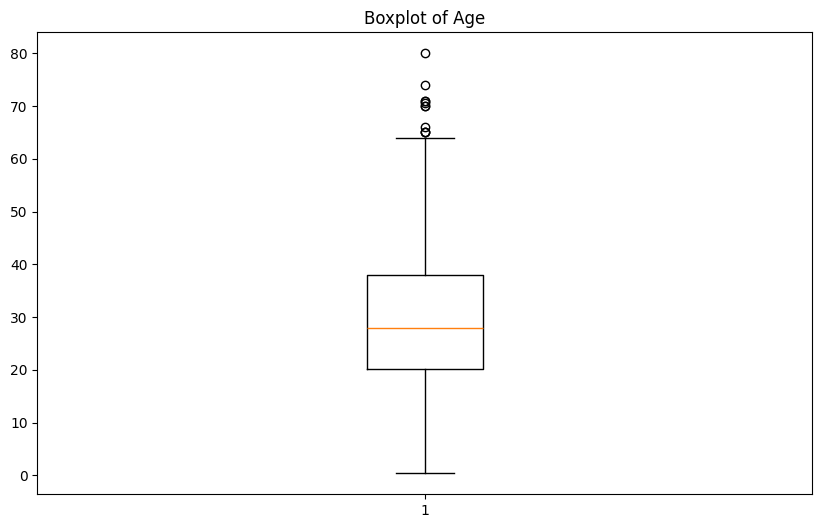

In [8]:
# Outliers - age
print(df['age'].describe())
plt.figure(figsize = (10,6))
plt.boxplot(df['age'].dropna())
plt.title("Boxplot of Age")
plt.show()

In [9]:
# IQR - age
Q1 =df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

17.875


In [10]:
lower = Q1 - 1.5*IQR
upper = Q3+ 1.5*IQR
print(lower)
print(upper)

-6.6875
64.8125


In [11]:
# display outliers - age
outliers = df[(df['age']<lower) | (df['age']>upper)]
print(outliers)

     survived  pclass   sex   age  sibsp  parch     fare embarked   class  \
33          0       2  male  66.0      0      0  10.5000        S  Second   
54          0       1  male  65.0      0      1  61.9792        C   First   
96          0       1  male  71.0      0      0  34.6542        C   First   
116         0       3  male  70.5      0      0   7.7500        Q   Third   
280         0       3  male  65.0      0      0   7.7500        Q   Third   
456         0       1  male  65.0      0      0  26.5500        S   First   
493         0       1  male  71.0      0      0  49.5042        C   First   
630         1       1  male  80.0      0      0  30.0000        S   First   
672         0       2  male  70.0      0      0  10.5000        S  Second   
745         0       1  male  70.0      1      1  71.0000        S   First   
851         0       3  male  74.0      0      0   7.7750        S   Third   

     who  adult_male  deck  embark_town alive  alone  
33   man        True

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: fare, dtype: float64


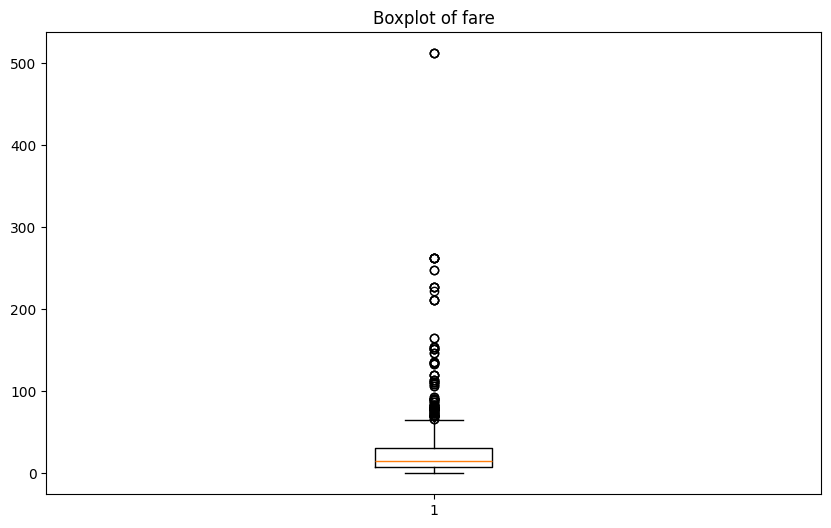

In [12]:
# Outliers - fare
print(df['fare'].describe())
plt.figure(figsize = (10,6))
plt.boxplot(df['fare'].dropna())
plt.title("Boxplot of fare")
plt.show()

In [13]:
# IQR - Fare
Q1 =df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

23.0896


In [14]:
lower = Q1 - 1.5*IQR
upper = Q3+ 1.5*IQR
print(lower)
print(upper)

-26.724
65.6344


In [15]:
# display outliers - fare
outliers = df[(df['fare']<lower) | (df['fare']>upper)]
print(outliers)

     survived  pclass     sex   age  sibsp  parch      fare embarked  class  \
1           1       1  female  38.0      1      0   71.2833        C  First   
27          0       1    male  19.0      3      2  263.0000        S  First   
31          1       1  female   NaN      1      0  146.5208        C  First   
34          0       1    male  28.0      1      0   82.1708        C  First   
52          1       1  female  49.0      1      0   76.7292        C  First   
..        ...     ...     ...   ...    ...    ...       ...      ...    ...   
846         0       3    male   NaN      8      2   69.5500        S  Third   
849         1       1  female   NaN      1      0   89.1042        C  First   
856         1       1  female  45.0      1      1  164.8667        S  First   
863         0       3  female   NaN      8      2   69.5500        S  Third   
879         1       1  female  56.0      0      1   83.1583        C  First   

       who  adult_male  deck  embark_town alive  al

In [16]:
from google.colab import files
df.to_csv("titanic_cleanedfile.csv", index= False)
files.download("titanic_cleanedfile.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
#  capping
df["age_original"] = df["age"]
df["age"] = df["age"].clip(lower,upper)
print(df[["age", "age_original"]].head(10))

    age  age_original
0  22.0          22.0
1  38.0          38.0
2  26.0          26.0
3  35.0          35.0
4  35.0          35.0
5   NaN           NaN
6  54.0          54.0
7   2.0           2.0
8  27.0          27.0
9  14.0          14.0


In [18]:
#  capping
df["age_original"] = df["age"]
df["age"] = df["age"].clip(lower,upper)
print(df[["age", "age_original"]].tail(10))

      age  age_original
881  33.0          33.0
882  22.0          22.0
883  28.0          28.0
884  25.0          25.0
885  39.0          39.0
886  27.0          27.0
887  19.0          19.0
888   NaN           NaN
889  26.0          26.0
890  32.0          32.0


In [19]:
print(df[["age", "age_original"]].head(35))

        age  age_original
0   22.0000       22.0000
1   38.0000       38.0000
2   26.0000       26.0000
3   35.0000       35.0000
4   35.0000       35.0000
5       NaN           NaN
6   54.0000       54.0000
7    2.0000        2.0000
8   27.0000       27.0000
9   14.0000       14.0000
10   4.0000        4.0000
11  58.0000       58.0000
12  20.0000       20.0000
13  39.0000       39.0000
14  14.0000       14.0000
15  55.0000       55.0000
16   2.0000        2.0000
17      NaN           NaN
18  31.0000       31.0000
19      NaN           NaN
20  35.0000       35.0000
21  34.0000       34.0000
22  15.0000       15.0000
23  28.0000       28.0000
24   8.0000        8.0000
25  38.0000       38.0000
26      NaN           NaN
27  19.0000       19.0000
28      NaN           NaN
29      NaN           NaN
30  40.0000       40.0000
31      NaN           NaN
32      NaN           NaN
33  65.6344       65.6344
34  28.0000       28.0000


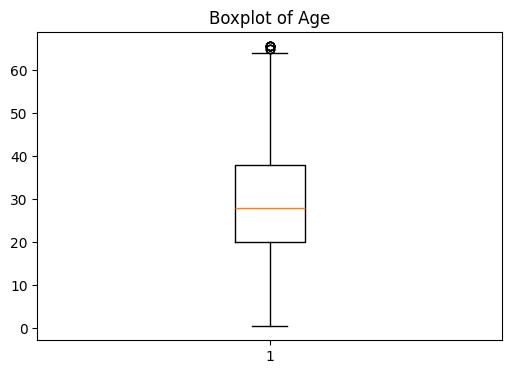

In [21]:
plt.figure(figsize=(6,4))
plt.boxplot(df["age"].dropna())
plt.title("Boxplot of Age")
plt.show()

In [25]:
# combining the datasets

df1 = pd.DataFrame({"Name": ["Aman", "Riya", "Rahul"],
                    "Age": [25, 22, 26]})

In [28]:
df2 = pd.DataFrame({"Name":["Kabir","Neha"],
                    "Age":[23, 24]})

In [29]:
print(df1)

    Name  Age
0   Aman   25
1   Riya   22
2  Rahul   26


In [30]:
print(df2)

    Name  Age
0  Kabir   23
1   Neha   24


In [31]:
combined_data = pd.concat([df1,df2], ignore_index=True)
print(combined_data)

    Name  Age
0   Aman   25
1   Riya   22
2  Rahul   26
3  Kabir   23
4   Neha   24


In [32]:
#  Merge
df3 = pd.DataFrame({"Name": ["Aman", "Riya", "Rahul"],
                    "Age": [25, 22, 26]})

In [33]:
df4 = pd.DataFrame({"Age":[25, 22, 26],
                    "Marks": [40,78,26]})

In [34]:
print(df3)

    Name  Age
0   Aman   25
1   Riya   22
2  Rahul   26


In [35]:
print(df4)

   Age  Marks
0   25     40
1   22     78
2   26     26


In [36]:
result = pd.merge(df3, df4, on="Age")
print(result)

    Name  Age  Marks
0   Aman   25     40
1   Riya   22     78
2  Rahul   26     26


In [39]:
# Left Join
r = pd.merge(df1, df2, how="left")
print(r)

    Name  Age
0   Aman   25
1   Riya   22
2  Rahul   26


In [40]:
# Right Join
r1 = pd.merge(df1, df2, how="right")
print(r1)

    Name  Age
0  Kabir   23
1   Neha   24


In [41]:
# outer Join
r2 = pd.merge(df1, df2, how="outer")
print(r2)

    Name  Age
0   Aman   25
1  Kabir   23
2   Neha   24
3  Rahul   26
4   Riya   22


In [42]:
# inner join
r3 = pd.merge(df1, df2, how="inner")
print(r3)

Empty DataFrame
Columns: [Name, Age]
Index: []
